In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [28]:
# Parameters
t = 1
s = 0
r = 0.8
p = 0.2
epsilon = 0.1
d = 0.9
alpha = 0.1
bound = 1 / (1 - d)

In [29]:
algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        random_uniform=False, tolerance=1e-10000, 
        M=int(50), verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()  
exp = np.random.randint(0, 5)
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]  

In [30]:
internal_debug = False
if internal_debug:
    q1['StateC'] = q1['Q1'] - q1['Q3']
    q1['StateD'] = q1['Q2'] - q1['Q4']
    q2['StateC'] = q2['Q1'] - q2['Q3']
    q2['StateD'] = q2['Q2'] - q2['Q4']
    x = q1['StateC'].values
    y = q2['StateC'].values
    z = q1['StateD'].values
    w = q2['StateD'].values
    pd.Series(x).plot(title='Q1-StateC', color='blue')
    pd.Series(y).plot(title='Q2-StateC', color='red')
    pd.Series(z).plot(title='Q1-StateD', color='green')
    pd.Series(w).plot(title='Q2-StateD', color='orange')
    plt.legend(['Q1-StateC', 'Q2-StateC', 'Q1-StateD', 'Q2-StateD'])


In [31]:
#q1.join(q2, rsuffix='_q2', lsuffix='_q1')


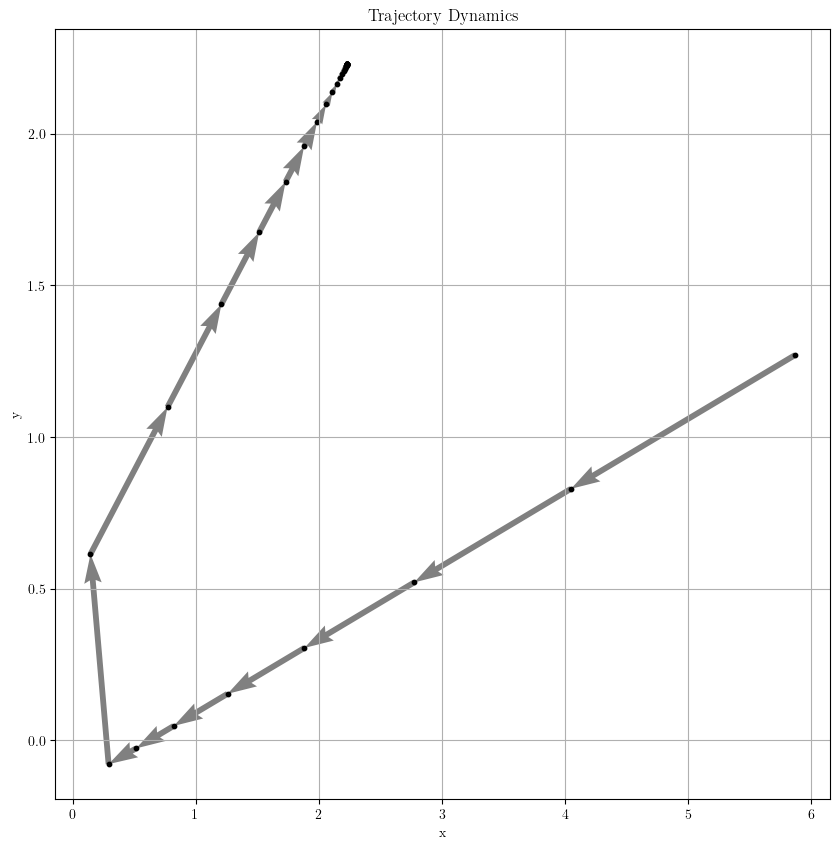

In [32]:
trajectory_dynamics_plot(x, y)

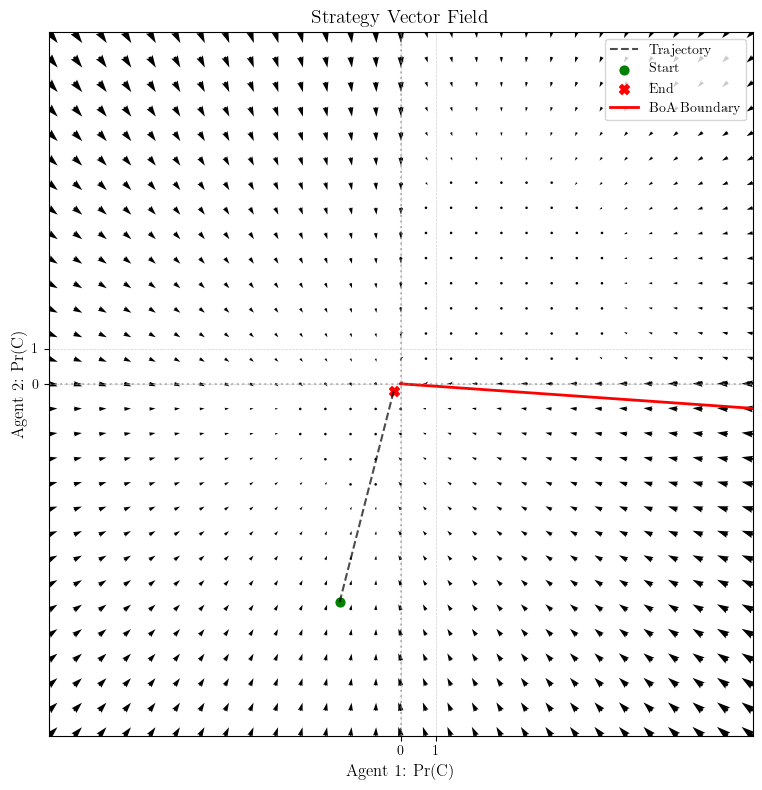

In [34]:
plotter = VectorFieldPlotter(q1 = q1, q2 = q2,
    t=t, r=r, p=p, s=s, alpha=alpha,
    bound=bound,
    epsilon=epsilon, delta=d,
    q_func_gt=QvaluesGTvsGT,
    q_func_ad=QvaluesADvs00, 
    x_state = 'StateC',
    y_state = 'StateC', method = "quiver",cmap=cm.viridis,
    show_trajectory=True,
    show_basin=True, 

)
plotter.plot()